# Burke GDP response at country level: GDP and GDP per capita

`ramip_impacts_gdp.ipynb` applies Burke, Hsiang and Miguel's growth response g(T) cell by cell. Burke's coefficients
come from a country-year panel of population-weighted mean temperature, so the natural unit is the country. Here,
for the global cleanup (`ssp370` vs `ssp370-126aer`) and the seven regional arms against their own `ssp370` parent at
matched GWL 2.0:

1. monthly `tas` on the 1° grid → **population-weighted country mean** (GHS-POP 2020, 30 arcsec, summed to 1°;
   GHS-POP 2030 as a sensitivity check) using fractional Natural Earth country masks (242 countries);
2. **Δg**: Burke's response applied to annual country temperature, averaged over the 10-year window, arm minus
   parent, in growth-rate units (0.001 = 0.1 percentage points of annual GDP-per-capita growth);
3. the block-permutation KS test on the two monthly country series of g(T) (12-month blocks, 999 draws), with a
   same-forcing null from every model's parent member pairs;
4. **ΔGDP per capita** = Δg × GDP per capita and **ΔGDP** = Δg × GDP (World Bank, constant 2015 US$, 2019).

Read 4 as "the change in one year's growth, valued at today's economy": a one-year growth-rate difference scaled by
present GDP, not a compounded damage projection; population weights are present-day. Only arm-to-arm differences are
meaningful, not levels. Sign convention: arm − parent, so negative means the aerosol-cleanup pathway is economically
worse at the same global temperature.

In [1]:
import os, re, warnings
os.environ.setdefault('ESMFMKFILE', '/burg-archive/home/mck2199/summer/.esmf/lib/esmf.mk')
import numpy as np
import pandas as pd
import xarray as xr

import sys
sys.path.insert(0, '/burg-archive/home/mck2199/summer/bcd_me/code')
sys.path.insert(0, '/burg-archive/home/mck2199/summer/bcd_me/path_independence')
from funcs_support import get_params
import ks_tools as kt

dir_list = get_params()
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

RAMIP   = dir_list['raw'] + 'ramip/'
SCEN    = dir_list['raw'] + 'scenariomip/'
PRODUCT = dir_list['aux'] + 'gwl_timeseries.zarr'
GWL_DIR = dir_list['aux'] + 'diagnostics/ramip_gwl/'
IMP_DIR = dir_list['aux'] + 'diagnostics/impacts/'
DL_DIR  = dir_list['aux'] + 'data_layer/'
POP_DIR = dir_list['raw'] + 'population/'
out_dir = dir_list['aux'] + '../figures/e7_gdp/'
for d in (IMP_DIR, DL_DIR, POP_DIR, out_dir):
    os.makedirs(d, exist_ok=True)

GWL, ALPHA, FDR = 2.0, 0.05, 0.2
ARMS = {'glob': 'ssp370-126aer', 'eas': 'ssp370-EAS126aer', 'sas': 'ssp370-SAS126aer', 'afr': 'ssp370-AFR126aer', 'nae': 'ssp370-NAE126aer',
        'asia': 'ssp370-ASIA126aer', 'safca': 'ssp370-SAF126ca', 'sasca': 'ssp370-SAS126ca'}

# anchor 1: own ssp370 parent (RAMIP)
PARENT = {m: 'ssp370' for m in ['CanESM5-1', 'CNRM-ESM2-1', 'EC-Earth3-AerChem', 'GISS-E2-1-G',
                                'MIROC6', 'MRI-ESM2-0', 'NorESM2-LM', 'UKESM1-0-LL']}
PARENT['CESM2'] = 'ssp370-LE'
_gmst = xr.open_zarr(PRODUCT, group='gmst')
_gwl  = xr.open_zarr(PRODUCT, group='gwl')
win_df = pd.read_csv(f'{GWL_DIR}gwl{GWL}_windows.csv')


def gwl_ends(mod, exp):
    ids = _gmst.run_id.sel(model=mod, exp=exp).values
    we  = _gwl.window_end.sel(model=mod, exp=exp, gwl=GWL).values
    return {str(r): int(e) for r, e in zip(ids, we) if r and np.isfinite(e)}


def parent_pairs(mod, arm_exp):
    """(run, parent_end, run, arm_end): the arm against its own parent run, as ks_gwl_1deg does
    for the East-Asia arm. Parent windows come from the audited gwl2.0_windows.csv."""
    ends = gwl_ends(mod, arm_exp)
    rows = win_df[(win_df.model == mod) & win_df.usable]
    return [(r.run, int(r.anchor_end), r.run, ends[r.run]) for _, r in rows.iterrows() if r.run in ends]




import geopandas as gpd
import regionmask
import rasterio, zipfile, requests
from rasterio.windows import Window

JOBS = {}
for arm, exp in ARMS.items():
    for m in PARENT:
        prs = parent_pairs(m, exp)
        if prs:
            JOBS[(arm, m)] = prs
print('comparisons:', {arm: sum(len(v) for (a, m), v in JOBS.items() if a == arm) for arm in ARMS}, 'pairs')
LAT, LON = kt.GRID_OUT['lat'], kt.GRID_OUT['lon']

comparisons: {'glob': 72, 'eas': 67, 'sas': 62, 'afr': 58, 'nae': 66, 'asia': 16, 'safca': 10, 'sasca': 12} pairs


## Population on the 1° grid (GHS-POP 2020 and 2030)

In [2]:
GHS = {2020: 'GHS_POP_E2020_GLOBE_R2023A_4326_30ss', 2030: 'GHS_POP_E2030_GLOBE_R2023A_4326_30ss'}
GHS_URL = 'https://jeodpp.jrc.ec.europa.eu/ftp/jrc-opendata/GHSL/GHS_POP_GLOBE_R2023A/{stem}/V1-0/{stem}_V1_0.zip'
POP_FN = DL_DIR + 'population_1deg.nc'


def fetch(url, fn):
    if not os.path.exists(fn):
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(fn + '.tmp', 'wb') as f:
                for chunk in r.iter_content(1 << 22):
                    f.write(chunk)
        os.rename(fn + '.tmp', fn)
    return fn


def ghs_to_1deg(year):
    """GHS-POP 30 arcsec (43200 x 21600, rows from 90N) summed to the 1deg grid (lat ascending, lon 0.5..359.5)"""
    stem = GHS[year]
    zf = fetch(GHS_URL.format(stem=stem), POP_DIR + stem + '_V1_0.zip')
    tif = POP_DIR + stem + '_V1_0.tif'
    if not os.path.exists(tif):
        with zipfile.ZipFile(zf) as z:
            z.extract(stem + '_V1_0.tif', POP_DIR)
    out = np.zeros(kt.NLAT * kt.NLON)
    with rasterio.open(tif) as src:                                 # grid is not degree-aligned: bin every pixel
        T = src.transform
        lons = T.c + (np.arange(src.width) + 0.5) * T.a
        ilon = np.floor(np.mod(lons, 360)).astype(int)              # our lon bins are 0..359 (centres 0.5..359.5)
        for r0 in range(0, src.height, 240):
            blk = src.read(1, window=Window(0, r0, src.width, min(240, src.height - r0))).astype('float64')
            blk[blk < 0] = 0                                        # nodata (-200) and anything negative
            lats = T.f + (r0 + np.arange(blk.shape[0]) + 0.5) * T.e
            ilat = np.clip(np.floor(lats + 90), 0, kt.NLAT - 1).astype(int)
            idx = (ilat[:, None] * kt.NLON + ilon[None, :]).ravel()
            out += np.bincount(idx, weights=blk.ravel(), minlength=out.size)
        print(f'  {stem}: {src.width} x {src.height} px, bounds {tuple(round(b, 3) for b in src.bounds)}')
    out = out.reshape(kt.NLAT, kt.NLON)
    return xr.DataArray(out, dims=('lat', 'lon'), coords={'lat': LAT, 'lon': LON}, attrs={'units': 'persons', 'source': stem})


if os.path.exists(POP_FN):
    pop = xr.open_dataset(POP_FN).load()
else:
    pop = xr.Dataset({f'pop{y}': ghs_to_1deg(y) for y in GHS})
    pop.attrs['source'] = 'GHS-POP R2023A (JRC), 30 arcsec WGS84, summed to 1 degree'
    pop.to_netcdf(POP_FN)
for y in GHS:
    print(f'GHS-POP {y}: {float(pop[f"pop{y}"].sum()) / 1e9:.2f} billion')

GHS-POP 2020: 7.84 billion
GHS-POP 2030: 8.55 billion


## Countries, World Bank GDP and population weights

In [3]:
NE_URL = 'https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip'
ne = gpd.read_file('zip://' + fetch(NE_URL, POP_DIR + 'ne_50m_admin_0_countries.zip'))
ne = ne.dissolve(by='ADM0_A3', aggfunc='first').reset_index()[['ADM0_A3', 'NAME', 'geometry']].rename(columns={'ADM0_A3': 'iso3', 'NAME': 'name'})
regions = regionmask.from_geopandas(ne, names='name', abbrevs='iso3', name='countries')
m3 = regions.mask_3D_frac_approx(LON, LAT).transpose('region', 'lat', 'lon')   # fractional cell coverage; regions with none are dropped
ne = ne.iloc[m3.region.values].reset_index(drop=True)
frac = m3.values
print(len(regions), 'countries;', len(ne), 'with coverage on the 1deg grid (the rest are islands smaller than a cell)')

# World Bank, constant-2015-US$ GDP and GDP per capita, population; 2019 (pre-COVID), else latest 2015-2022
WB_FN = DL_DIR + 'worldbank_gdp_pop.csv'
if os.path.exists(WB_FN):
    wb = pd.read_csv(WB_FN, index_col=0)
else:
    cols = {'NY.GDP.PCAP.KD': 'gdp_pc', 'NY.GDP.MKTP.KD': 'gdp', 'SP.POP.TOTL': 'pop_wb'}
    frames = []
    for ind, col in cols.items():
        r = requests.get(f'https://api.worldbank.org/v2/country/all/indicator/{ind}',
                         params={'format': 'json', 'date': '2015:2022', 'per_page': 5000}, timeout=120).json()[1]
        d = pd.DataFrame([{'iso3': x['countryiso3code'], 'year': int(x['date']), col: x['value']} for x in r if x['countryiso3code']])
        d = d.dropna().sort_values('year')
        best = pd.concat([d[d.year == 2019], d]).drop_duplicates('iso3', keep='first').set_index('iso3')   # 2019 first
        frames.append(best[[col]].assign(**{col + '_year': best.year}))
    wb = pd.concat(frames, axis=1)
    wb.to_csv(WB_FN)
ALIAS = {'KOS': 'XKX', 'SDS': 'SSD', 'PSX': 'PSE'}                     # Natural Earth code -> World Bank code
ne['iso_wb'] = ne.iso3.map(lambda c: ALIAS.get(c, c))
ne = ne.join(wb[['gdp_pc', 'gdp', 'pop_wb']], on='iso_wb')
print('countries with World Bank GDP:', int(ne.gdp.notna().sum()), '| without:', ', '.join(ne[ne.gdp.isna()].name.head(25)), '...')

# country weights: population (2020 main, 2030 sensitivity); area where a country has no population cells
cosw = np.cos(np.deg2rad(LAT))[:, None] * np.ones(kt.NLON)
def weights(popgrid):
    w = frac * popgrid.values[None]
    empty = w.sum((1, 2)) == 0
    w[empty] = (frac * cosw[None])[empty]
    return w / np.maximum(w.sum((1, 2), keepdims=True), 1e-12)
W20, W30 = weights(pop.pop2020), weights(pop.pop2030)
print('countries falling back to area weights:', int(((frac * pop.pop2020.values[None]).sum((1, 2)) == 0).sum()))

242 countries; 228 with coverage on the 1deg grid (the rest are islands smaller than a cell)
countries with World Bank GDP: 205 | without: Anguilla, Åland, Antarctica, Fr. S. Antarctic Lands, N. Cyprus, Eritrea, Falkland Is., Guernsey, Heard I. and McDonald Is., Br. Indian Ocean Ter., Jersey, Siachen Glacier, Norfolk Island, Niue, North Korea, W. Sahara, S. Geo. and the Is., Saint Helena, Somaliland, St. Pierre and Miquelon, Taiwan, British Virgin Is., Wallis and Futuna Is. ...


countries falling back to area weights: 5


## Country series, Burke response, KS test and same-forcing null

Cached in `diagnostics/impacts/burke_country_pairs.csv` (one row per comparison × model × pair × country) and `burke_country_null.csv`.

In [4]:
PAIR_FN = IMP_DIR + 'burke_country_pairs.csv'
NULL_FN = IMP_DIR + 'burke_country_null.csv'
burke = lambda t_c: kt.B1 * t_c + kt.B2 * t_c ** 2      # Burke g(T) on degC (kt.burke_growth takes kelvin)
n_c = len(ne)


def country_series(fn, end, w):
    """monthly country-mean temperature (degC), (countries, 120), weights w (countries, lat, lon)"""
    da = kt.window_1deg(fn, 'tas', end)
    if da is None or da.sizes['time'] != 12 * kt.WIN:
        return None
    return np.einsum('clk,tlk->ct', w, da.values) - 273.15


def dg_annual(Tp, Ta):
    """Burke's response on annual country temperature, window mean, arm minus parent"""
    gp = burke(Tp.reshape(n_c, kt.WIN, 12).mean(-1)).mean(-1)
    ga = burke(Ta.reshape(n_c, kt.WIN, 12).mean(-1)).mean(-1)
    return ga - gp


if os.path.exists(PAIR_FN) and os.path.exists(NULL_FN):
    pairs = pd.read_csv(PAIR_FN); null = pd.read_csv(NULL_FN)
    print('loaded', len(pairs), 'pair-country rows and', len(null), 'null rows')
else:
    rows, nrows, cache = [], [], {}

    def parent(mod, run, end, fn):
        key = (mod, run, end)
        if key not in cache:
            cache[key] = (country_series(fn, end, W20), country_series(fn, end, W30))
        return cache[key]

    for mod in PARENT:
        pfns = kt.member_files(RAMIP, mod, PARENT[mod])
        for arm, exp in ARMS.items():
            prs = JOBS.get((arm, mod))
            if not prs:
                continue
            afns = kt.member_files(RAMIP, mod, exp)
            for run, ep, _, ea in prs:
                if run not in pfns or run not in afns:
                    continue
                Tp, Tp30 = parent(mod, run, ep, pfns[run])
                Ta, Ta30 = country_series(afns[run], ea, W20), country_series(afns[run], ea, W30)
                if Tp is None or Ta is None:
                    print(f'  {arm} {mod} {run}: short window, skipped'); continue
                p = kt.block_perm_map(burke(Tp), burke(Ta))                       # KS on the monthly g(T) series
                d20, d30 = dg_annual(Tp, Ta), dg_annual(Tp30, Ta30)
                for c in range(n_c):
                    rows.append({'arm': arm, 'model': mod, 'run': run, 'iso3': ne.iso3[c], 'T_parent': Tp[c].mean(),
                                 'dT': Ta[c].mean() - Tp[c].mean(), 'dg': d20[c], 'dg_pop2030': d30[c], 'p': p[c]})
            print(f'{arm} {mod}: done', flush=True)
        # same-forcing null: every pair of this model's parent members, at their own windows
        keys = [k for k in cache if k[0] == mod]
        for i, k1 in enumerate(keys):
            for k2 in keys[i + 1:]:
                p = kt.block_perm_map(burke(cache[k1][0]), burke(cache[k2][0]))
                for c in range(n_c):
                    nrows.append({'model': mod, 'pair': f'{k1[1]}|{k2[1]}', 'iso3': ne.iso3[c], 'p': p[c],
                                  'dg': dg_annual(cache[k1][0], cache[k2][0])[c]})
        cache = {k: v for k, v in cache.items() if k[0] != mod}
    pairs, null = pd.DataFrame(rows), pd.DataFrame(nrows)
    pairs.to_csv(PAIR_FN, index=False); null.to_csv(NULL_FN, index=False)
    print('saved', len(pairs), 'pair-country rows,', len(null), 'null rows')

loaded 82764 pair-country rows and 68400 null rows


## Summaries

`burke_country_summary.csv` (per comparison × country), `burke_country_by_model.csv`, `burke_country_totals.csv`. Money numbers use the mean of per-model means so a model with more pairs does not dominate.

In [5]:
econ = ne.set_index('iso3')[['name', 'gdp_pc', 'gdp', 'pop_wb']]
pairs = pairs.join(econ, on='iso3')
pairs['dgdp_pc'] = pairs.dg * pairs.gdp_pc            # US$ per person per year of growth difference
pairs['dgdp'] = pairs.dg * pairs.gdp                  # US$ per year
null_c = null.groupby('iso3').p.apply(lambda s: (s < ALPHA).mean()).rename('null_reject')
null_m = null.groupby(['model', 'iso3']).p.apply(lambda s: (s < ALPHA).mean())

bym = pairs.groupby(['arm', 'model', 'iso3']).agg(pairs=('run', 'size'), dg=('dg', 'mean'), dT=('dT', 'mean'),
                                                   reject=('p', lambda s: (s < ALPHA).mean())).reset_index()
summ = (pairs.groupby(['arm', 'iso3'])
             .agg(models=('model', 'nunique'), pairs=('run', 'size'), T_parent=('T_parent', 'mean'), dT=('dT', 'mean'),
                  dg=('dg', 'mean'), dg_sd=('dg', 'std'), dg_pop2030=('dg_pop2030', 'mean'),
                  agree=('dg', lambda s: max((s > 0).mean(), (s < 0).mean())), reject=('p', lambda s: (s < ALPHA).mean()))
             .reset_index().join(econ, on='iso3').join(null_c, on='iso3'))
# model-mean of per-model means, so a model with more pairs does not dominate the money numbers
mm = bym.groupby(['arm', 'iso3']).dg.mean().rename('dg_modelmean')
summ = summ.join(mm, on=['arm', 'iso3'])
summ['dgdp_pc'] = summ.dg_modelmean * summ.gdp_pc
summ['dgdp'] = summ.dg_modelmean * summ.gdp
summ.to_csv(IMP_DIR + 'burke_country_summary.csv', index=False)
bym.to_csv(IMP_DIR + 'burke_country_by_model.csv', index=False)

# totals per arm: sum of country dGDP per model, then mean and spread over models
tot = (bym.join(econ, on='iso3').assign(dgdp=lambda d: d.dg * d.gdp, w=lambda d: d.pop_wb)
          .groupby(['arm', 'model']).apply(lambda d: pd.Series({'dgdp_bn': d.dgdp.sum() / 1e9,
                                                                 'dg_popw': np.average(d.dg, weights=d.w.fillna(0) + 1e-9),
                                                                 'countries': len(d)})).reset_index())
totals = tot.groupby('arm').agg(models=('model', 'nunique'), dgdp_bn=('dgdp_bn', 'mean'), dgdp_bn_sd=('dgdp_bn', 'std'),
                                dg_popw=('dg_popw', 'mean'), dg_popw_sd=('dg_popw', 'std')).round(4)
totals.to_csv(IMP_DIR + 'burke_country_totals.csv')
pd.set_option('display.width', 220)
print('world totals, arm minus parent at matched GWL 2.0 (constant 2015 US$ bn per year of growth difference; '
      'population-weighted mean dg in growth units):')
print(totals.to_string())
print(f'\nnull: same-forcing parent pairs reject {null_c.mean():.3f} of countries on average (range {null_c.min():.2f}-{null_c.max():.2f})')
g = summ[summ.arm == 'glob'].dropna(subset=['gdp'])
print('\nglobal cleanup: 12 largest |dGDP| countries (dg = growth units, dgdp_pc US$/person/yr, dgdp US$ bn/yr; reject = fraction of pairs p<0.05):')
show = g.reindex(g.dgdp.abs().sort_values(ascending=False).index).head(12)
print(show.assign(dgdp=show.dgdp / 1e9)[['name', 'models', 'pairs', 'dT', 'dg', 'dg_sd', 'agree', 'reject', 'null_reject', 'dgdp_pc', 'dgdp']].round(4).to_string(index=False))
print('\nsensitivity to population weights (2030 vs 2020): mean |dg difference| =', round(float((summ.dg - summ.dg_pop2030).abs().mean()), 6))
for arm in ['eas', 'sas', 'afr', 'nae']:
    s = summ[summ.arm == arm].dropna(subset=['gdp'])
    top = s.reindex(s.dg.abs().sort_values(ascending=False).index).head(6)
    print(f'\n{ARMS[arm]}: 6 largest |dg| countries'); print(top.assign(dgdp=top.dgdp / 1e9)[['name', 'models', 'pairs', 'dT', 'dg', 'agree', 'reject', 'dgdp_pc', 'dgdp']].round(4).to_string(index=False))

world totals, arm minus parent at matched GWL 2.0 (constant 2015 US$ bn per year of growth difference; population-weighted mean dg in growth units):
       models  dgdp_bn  dgdp_bn_sd  dg_popw  dg_popw_sd
arm                                                    
afr         8  -2.4375     18.3051  -0.0000      0.0005
asia        2 -35.2467     40.8122  -0.0011      0.0010
eas         8 -17.7293     18.0735  -0.0002      0.0004
glob        8 -41.8894     35.6844  -0.0012      0.0007
nae         8  -0.4790     17.3812   0.0003      0.0006
safca       2 -27.4696     30.8428  -0.0003      0.0001
sas         7 -13.5667     10.3751  -0.0008      0.0005
sasca       3   3.9842     16.8661   0.0003      0.0010

null: same-forcing parent pairs reject 0.047 of countries on average (range 0.00-0.19)

global cleanup: 12 largest |dGDP| countries (dg = growth units, dgdp_pc US$/person/yr, dgdp US$ bn/yr; reject = fraction of pairs p<0.05):
                    name  models  pairs      dT      dg  dg_sd 

## Into the data product

Group `burke_country` in `gwl_timeseries.zarr`: `dT`, `dg`, `dg_pop2030`, `p` on `(arm, model, pair, country)` with
`run_id`, and the country table (`name`, `gdp_pc`, `gdp`, `pop_wb`) as coordinates; `member`-style sparsity (NaN where a
combination does not exist).

In [6]:
import shutil
G = 'burke_country'
pairs['pair'] = pairs.groupby(['arm', 'model']).run.transform(lambda s: pd.factorize(s)[0])
cube = (pairs.set_index(['arm', 'model', 'pair', 'iso3'])[['dT', 'dg', 'dg_pop2030', 'p']].to_xarray()
             .rename({'iso3': 'country'}))
rid = pairs.drop_duplicates(['arm', 'model', 'pair']).set_index(['arm', 'model', 'pair']).run.to_xarray().fillna('').astype('U40')
cube['run_id'] = rid
ct = econ.reindex(cube.country.values)
cube = cube.assign_coords(name=('country', ct.name.values.astype('U60')), gdp_pc=('country', ct.gdp_pc.values),
                          gdp=('country', ct.gdp.values), pop_wb=('country', ct.pop_wb.values))
cube.dg.attrs = {'long_name': 'Burke growth response on annual population-weighted country temperature, window mean, arm minus parent', 'units': 'growth-rate units (0.001 = 0.1 pp)'}
cube.dT.attrs = {'long_name': 'population-weighted country temperature, arm minus parent', 'units': 'K'}
cube.p.attrs = {'long_name': 'block-permutation KS p of the two monthly g(T) country series (12-month blocks, 999 draws)'}
cube.attrs = {'group': G, 'created_by': 'path_independence/pipeline/ramip_impacts_gdp_country.ipynb', 'gwl': GWL,
              'population': 'GHS-POP R2023A 2020 (dg) and 2030 (dg_pop2030), summed to 1deg', 'economy': 'World Bank, constant 2015 US$, 2019',
              'arm': ', '.join(f'{a} = {e}' for a, e in ARMS.items()), 'null': f'same-forcing parent pairs reject {null_c.mean():.3f} of countries'}
shutil.rmtree(f'{PRODUCT}/{G}', ignore_errors=True)
for v in list(cube.variables):
    cube[v].encoding = {}
cube.to_zarr(PRODUCT, group=G, mode='a')
chk = xr.open_zarr(PRODUCT, group=G)
print('wrote group', G, dict(chk.sizes))

wrote group burke_country {'arm': 8, 'model': 8, 'pair': 10, 'country': 228}


## Figures

`burke_country_{arm}.png`: Δ growth rate, Δ GDP per capita, Δ GDP and the KS rejection fraction by country; `burke_country_top20_glob.png`: the 20 largest absolute GDP effects of global cleanup with the model spread.

saved /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e7_gdp/burke_country_glob.png


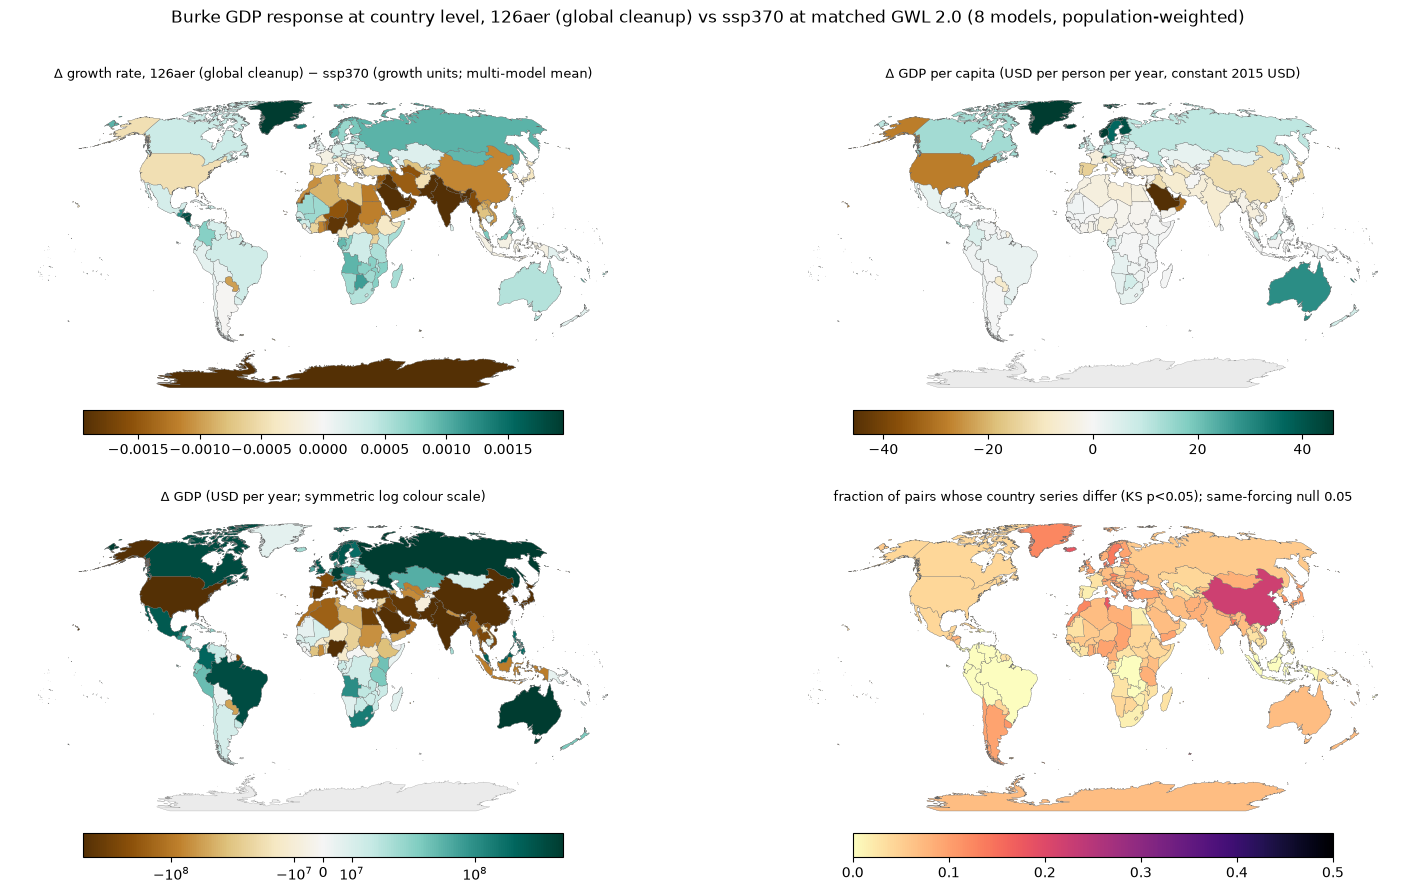

saved /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e7_gdp/burke_country_eas.png


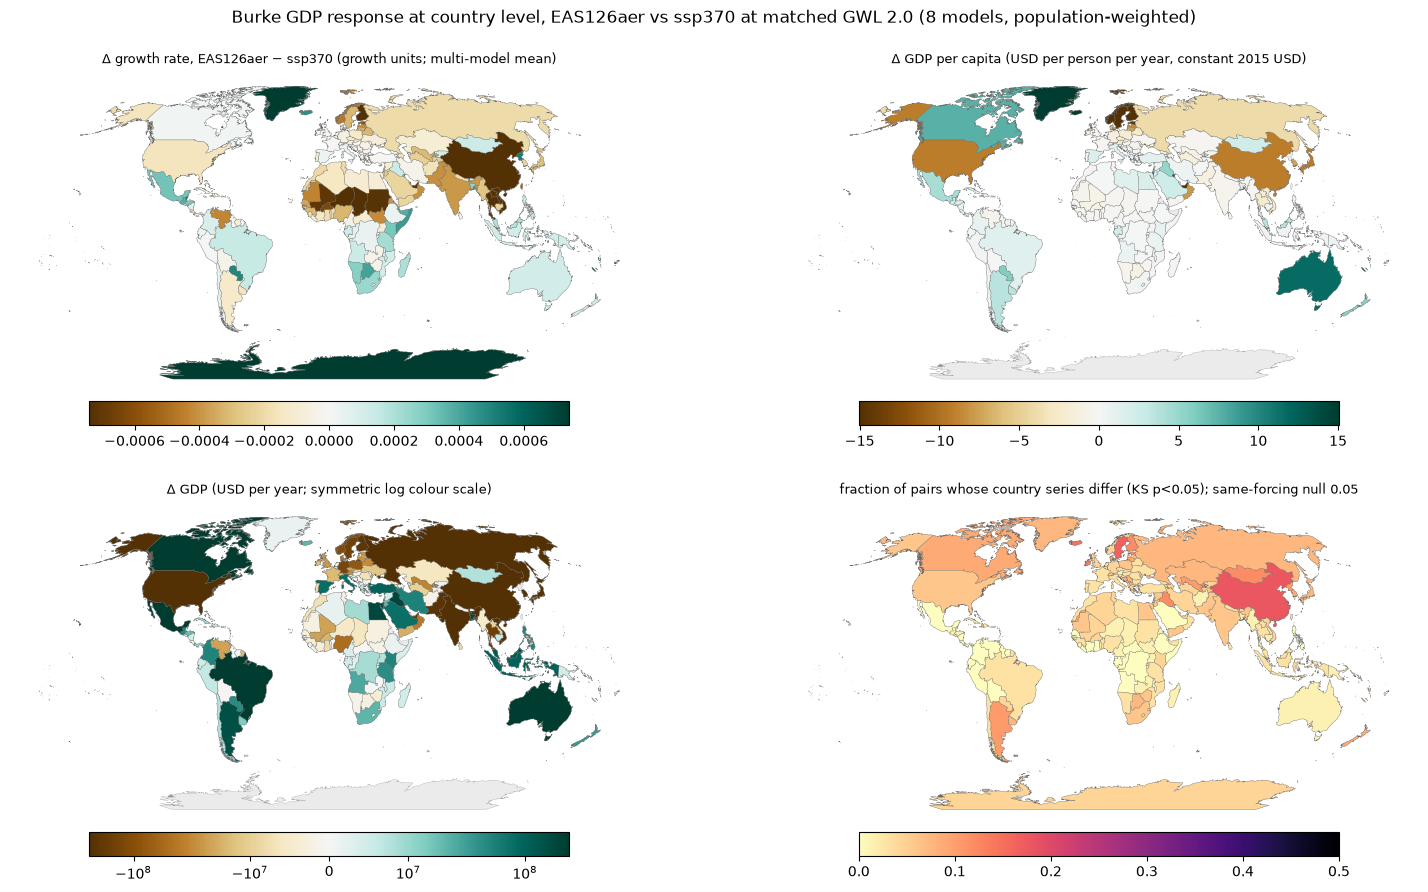

saved /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e7_gdp/burke_country_sas.png


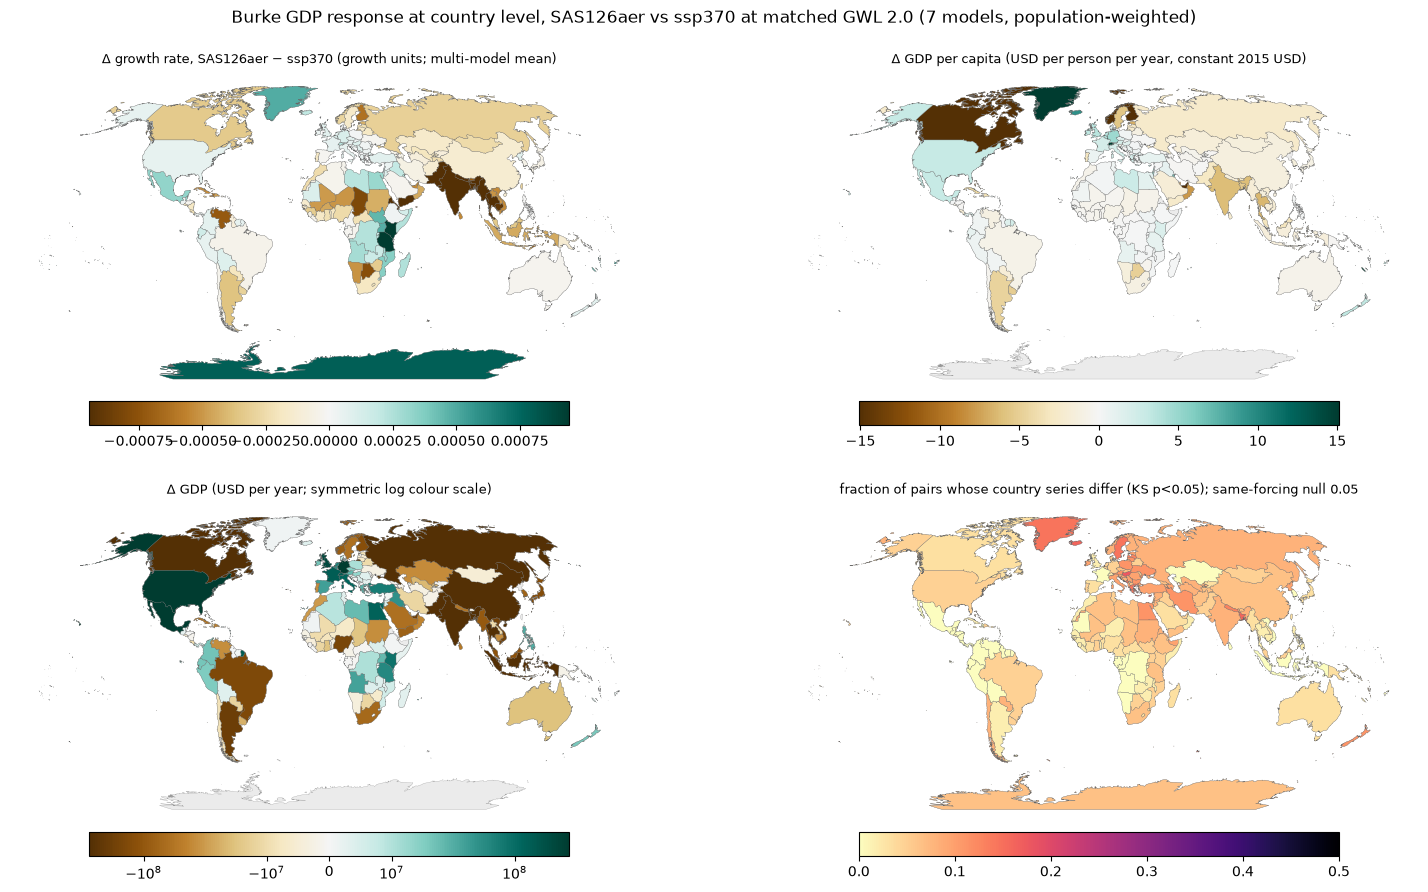

saved /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e7_gdp/burke_country_afr.png


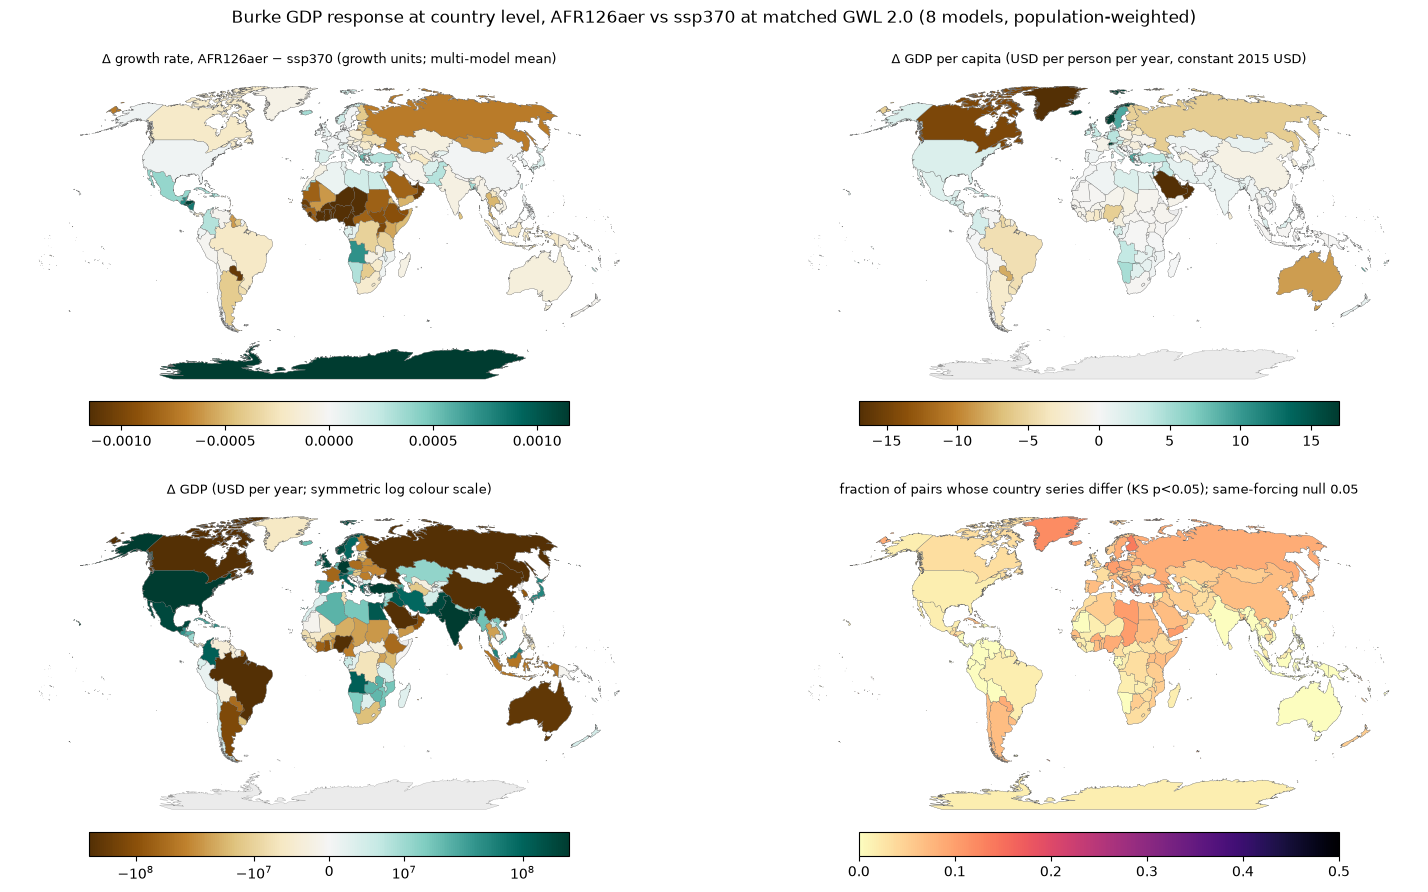

saved /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e7_gdp/burke_country_nae.png


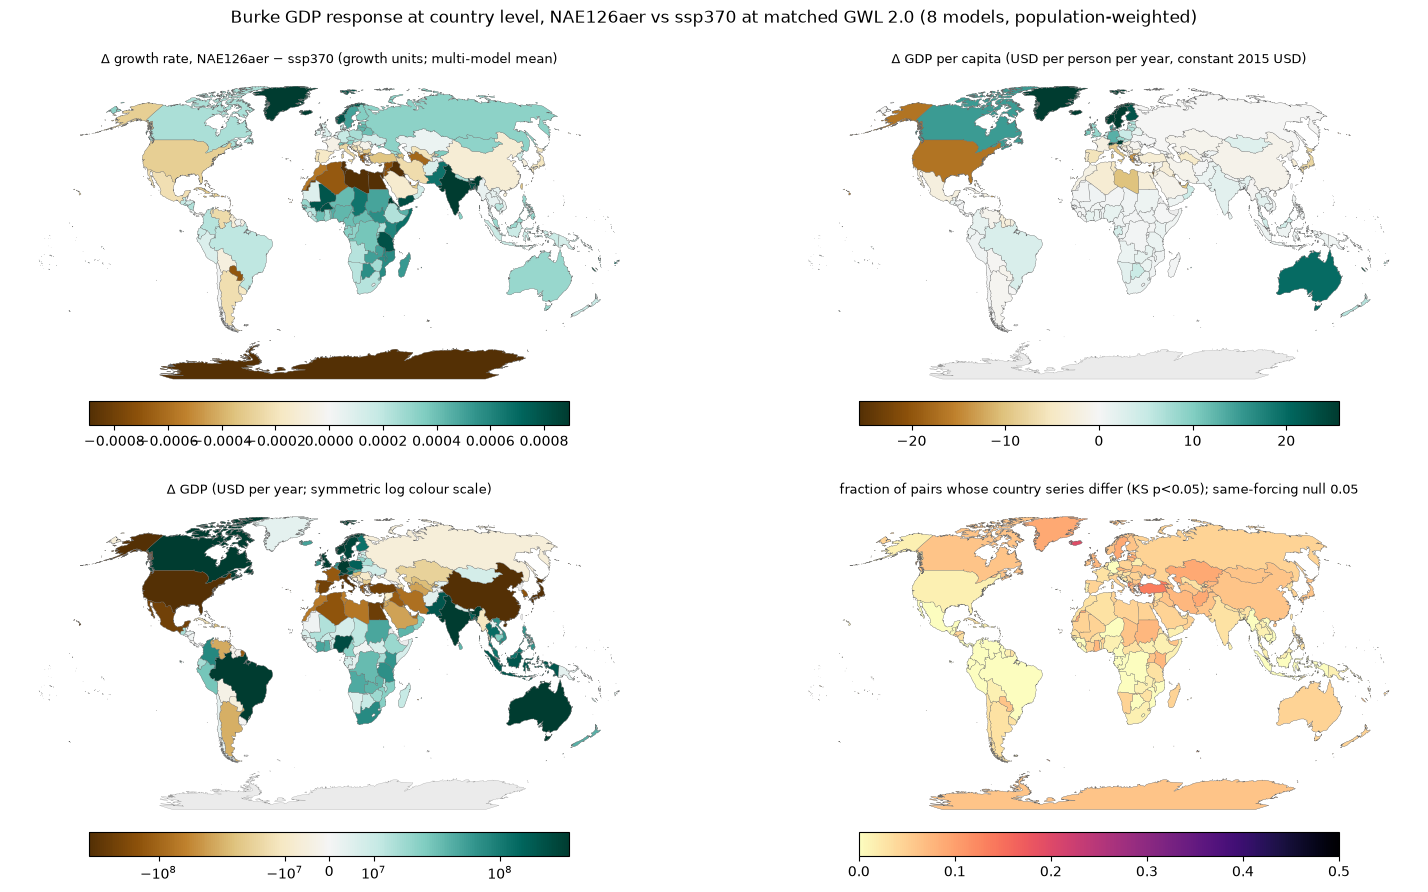

saved /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e7_gdp/burke_country_top20_glob.png


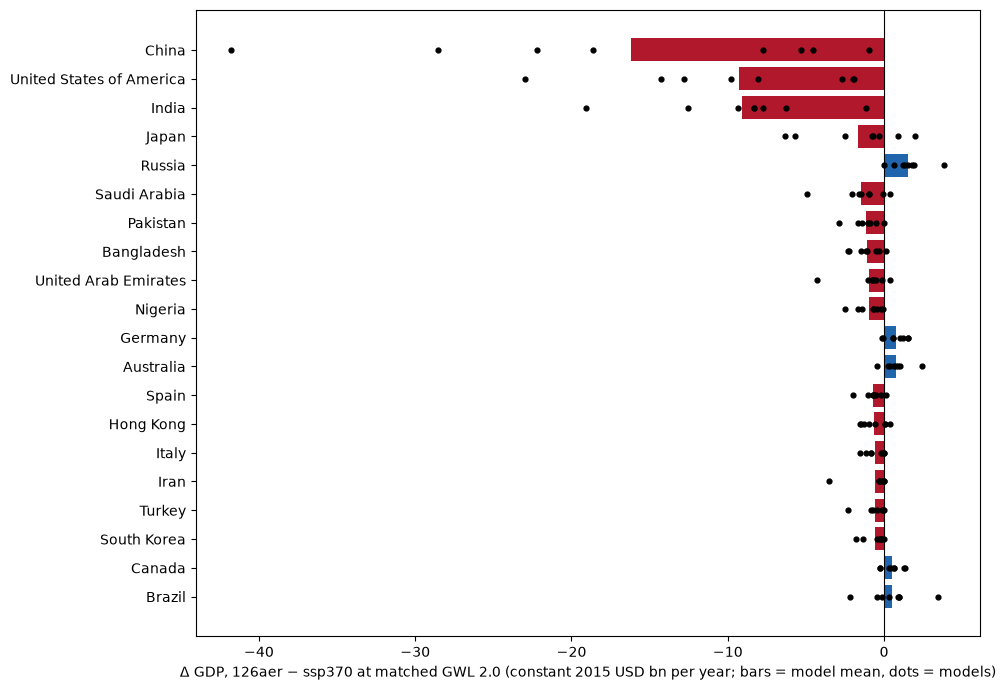

In [7]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
LABEL = {'glob': '126aer (global cleanup)', 'eas': 'EAS126aer', 'sas': 'SAS126aer', 'asia': 'ASIA126aer', 'afr': 'AFR126aer',
         'nae': 'NAE126aer', 'safca': 'SAF126ca', 'sasca': 'SAS126ca'}
world = ne.to_crs('ESRI:54030')          # Robinson


def choropleth(ax, arm, col, title, cmap, lim=None, log=False):
    d = world.join(summ[summ.arm == arm].set_index('iso3')[[col]], on='iso3')
    v = d[col]
    if lim is None:
        lim = float(np.nanpercentile(v.abs(), 95))
    norm = mcolors.SymLogNorm(linthresh=lim / 20, vmin=-lim, vmax=lim) if log else mcolors.Normalize(-lim, lim)
    world.plot(ax=ax, color='0.92', edgecolor='0.6', linewidth=0.2)
    d.dropna(subset=[col]).plot(ax=ax, column=col, cmap=cmap, norm=norm, edgecolor='0.4', linewidth=0.2, legend=True,
                                legend_kwds={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.02})
    ax.set_title(title, fontsize=9); ax.set_axis_off()


for arm in ['glob', 'eas', 'sas', 'afr', 'nae']:
    fig, axs = plt.subplots(2, 2, figsize=(16, 9))
    n = summ[summ.arm == arm].models.max()
    choropleth(axs[0, 0], arm, 'dg', f'Δ growth rate, {LABEL[arm]} − ssp370 (growth units; multi-model mean)', 'BrBG')
    choropleth(axs[0, 1], arm, 'dgdp_pc', 'Δ GDP per capita (USD per person per year, constant 2015 USD)', 'BrBG')
    choropleth(axs[1, 0], arm, 'dgdp', 'Δ GDP (USD per year; symmetric log colour scale)', 'BrBG', log=True)
    d = world.join(summ[summ.arm == arm].set_index('iso3')[['reject', 'null_reject']], on='iso3')
    world.plot(ax=axs[1, 1], color='0.92', edgecolor='0.6', linewidth=0.2)
    d.dropna(subset=['reject']).plot(ax=axs[1, 1], column='reject', cmap='magma_r', vmin=0, vmax=0.5, edgecolor='0.4', linewidth=0.2,
                                     legend=True, legend_kwds={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.02})
    axs[1, 1].set_title(f'fraction of pairs whose country series differ (KS p<{ALPHA}); same-forcing null {null_c.mean():.2f}', fontsize=9)
    axs[1, 1].set_axis_off()
    fig.suptitle(f'Burke GDP response at country level, {LABEL[arm]} vs ssp370 at matched GWL 2.0 ({n} models, population-weighted)', y=0.995)
    fig.tight_layout()
    fn = out_dir + f'burke_country_{arm}.png'
    fig.savefig(fn, dpi=140, bbox_inches='tight'); print('saved', fn); plt.show()

# largest absolute GDP effects for global cleanup, with the model spread
g = summ[summ.arm == 'glob'].dropna(subset=['gdp'])
top = g.reindex(g.dgdp.abs().sort_values(ascending=False).index).head(20)
per_model = bym[bym.arm == 'glob'].join(econ, on='iso3'); per_model['dgdp'] = per_model.dg * per_model.gdp
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.name, top.dgdp / 1e9, color=np.where(top.dgdp < 0, '#b2182b', '#2166ac'))
for i, iso in enumerate(top.iso3):
    pm = per_model[per_model.iso3 == iso].dgdp / 1e9
    ax.scatter(pm, np.full(len(pm), i), s=12, color='k', zorder=3)
ax.axvline(0, color='k', lw=0.8); ax.invert_yaxis()
ax.set_xlabel('Δ GDP, 126aer − ssp370 at matched GWL 2.0 (constant 2015 USD bn per year; bars = model mean, dots = models)')
fig.tight_layout(); fn = out_dir + 'burke_country_top20_glob.png'
fig.savefig(fn, dpi=150, bbox_inches='tight'); print('saved', fn); plt.show()

## Reading the results

**At matched 2 °C the global aerosol-cleanup pathway is economically slightly worse than ssp370 in Burke's framework,
because it is warmer where people live.** Population-weighted Δg = −0.0012 ± 0.0007 growth units (−0.12 percentage
points of one year's GDP-per-capita growth; 8 models), ΔGDP = −42 ± 36 bn US$ per year at constant 2015 prices, about
0.05 % of world GDP, with the model spread as large as the mean. The cleanup warms the populated northern mid-latitudes
relative to the global mean (China +0.35 K, Bangladesh +0.29 K, India +0.22 K, the US +0.14 K; Australia −0.08 K), and
most of those countries sit above Burke's 12.7 °C optimum, so the loss concentrates in China (−16 bn), the United States
(−9 bn) and India (−9 bn); Russia, Germany and Australia gain 0.7–1.5 bn. Sign agreement across the 72 pairs is 0.68–0.93
for the largest countries.

**Regional arms.** EAS126aer −18 ± 18 bn (China −13 bn), SAS126aer −14 ± 10 bn (India −8.7 bn, Bangladesh −0.9 bn),
AFR126aer −2 ± 18 bn (Nigeria −1.2 bn), NAE126aer −0.5 ± 17 bn; the two-model ASIA and carbonaceous arms are too few to
read. The losses sit inside each arm's own region, consistent with the in-box temperature fingerprint of
`ks_regional_arms.ipynb`.

**Detectability.** The block-permutation KS on the country series rejects for 4–22 % of pairs against a same-forcing
null of 4.7 %: China 22 %, Bangladesh 14 %, Nepal 13 %, most countries at the null. As at the grid-cell level, the
distributional test sees the difference only where the warming shift is largest; the effect-size numbers above are the
result.

**Sensitivity and caveats.** Weighting with 2030 instead of 2020 population changes Δg by 4 × 10⁻⁶ on average
(negligible). The money numbers are a one-year growth-rate response valued at today's economy (World Bank 2019,
constant 2015 US$): not compounded, no adaptation, Burke's pooled no-lag specification; 23 small territories without
World Bank GDP (and Antarctica) carry Δg but no money; 5 uninhabited units use area weights. Only arm-to-arm
differences are meaningful, never levels.